#   Ayudantía 8: Resolución EF3


In [ ]:
!pip install osmnx -q

In [ ]:
import os, urllib.request, zipfile, unicodedata
from itertools import combinations, permutations
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import osmnx as ox
from shapely.geometry import Point, LineString, box
from shapely.ops import unary_union

In [ ]:
# descargar los datos del curso (solo si no existen)
if not os.path.exists("datos_geoespaciales"):
    zip_url = "https://raw.githubusercontent.com/IIC2115/Syllabus/main/Material%20de%20clases/Cap%C3%ADtulo%203/Notebooks/datos_geoespaciales.zip"
    urllib.request.urlretrieve(zip_url, "datos_geoespaciales.zip")   # descarga el zip
    with zipfile.ZipFile("datos_geoespaciales.zip", "r") as z:
        z.extractall(".")                                              # lo descomprime en la carpeta actual
    print("datos descargados")
else:
    print("datos ya disponibles")

datos ya disponibles


## Paso 1: carga de datos

> **Comando: `gpd.read_file(ruta)`**
> - **Recibe:** la ruta de un archivo geográfico (`.shp`, `.geojson`).
> - **Devuelve:** una **GeoDataFrame**: una tabla de pandas con una columna extra, `geometry`.

In [ ]:
ruta = "datos_geoespaciales/"

estaciones = gpd.read_file(ruta + "Metro 2020/Estaciones_2020/Estaciones_2020.shp")
estaciones.head()   # .head() muestra las primeras 5 filas

,OBJECTID,ID_LINEA,LINEA,ESTACION,NOMBRE,POINT_X,POINT_Y,geometry
0,2,2,L2,EL PARRON,El Parrón,345717.3664,6.289105e+06,POINT (345717.366 6289105.444)
1,3,5,L5,CUMMING,Cumming,344899.1198,6.298782e+06,POINT (344899.12 6298781.571)
2,4,5,L5,QUINTA NORMAL,Quinta Normal,343809.1081,6.298628e+06,POINT (343808.803 6298622.125)
3,5,7,L4A,SAN RAMON,San Ramón,346685.4133,6.287624e+06,POINT (347436.975 6287501.27)
4,6,7,L4A,SANTA ROSA,Santa Rosa,348282.5816,6.287378e+06,POINT (348282.582 6287378.409)


Cada fila es una estación y su `geometry` es un punto.

El **CRS** (sistema de coordenadas) dice en qué unidades están las coordenadas. En grados (EPSG:4326), una distancia de "0.01" no sirve para nada. Por eso trabajamos todo en **EPSG:32719**, que mide en **metros**.

> **Comando nuevo: `tabla.to_crs(crs)`**
> - **Recibe:** el código del sistema de coordenadas al que queremos pasar.
> - **Devuelve:** la misma tabla con las coordenadas convertidas. No cambia la original: hay que guardar el resultado.

In [ ]:
CRS_METROS = "EPSG:32719"

print("CRS original:", estaciones.crs)
estaciones = estaciones.to_crs(CRS_METROS)
print("CRS nuevo:   ", estaciones.crs)

CRS original: EPSG:32719
CRS nuevo:    EPSG:32719


Cargamos el resto igual: `read_file(...)` y luego `.to_crs(CRS_METROS)`, encadenados en una línea.

Las cuatro bases de accidentes las guardamos en un **diccionario**: `accidentes["motos"]` es la tabla de motos.

In [ ]:
comunas = gpd.read_file(ruta + "Comunas/comunas.shp").to_crs(CRS_METROS)
distritos = gpd.read_file(ruta + "Distritos Censales/Distritos Censales RM.shp").to_crs(CRS_METROS)
areas = gpd.read_file(ruta + "Areas Urbanas/areas_urbanas.shp").to_crs(CRS_METROS)
lineas_metro = gpd.read_file(ruta + "Metro 2020/Lineas_2020/Lineas_2020.shp").to_crs(CRS_METROS)

accidentes = {
    "atropellos": gpd.read_file(ruta + "Accidentes/Atropellos_2020.geojson").to_crs(CRS_METROS),
    "bicicletas": gpd.read_file(ruta + "Accidentes/Bicicletas_2019.geojson").to_crs(CRS_METROS),
    "motos": gpd.read_file(ruta + "Accidentes/Motocicletas_2019.geojson").to_crs(CRS_METROS),
    "criticos": gpd.read_file(ruta + "Accidentes/Puntos_criticos_2019.geojson").to_crs(CRS_METROS),
}

print("comunas:", len(comunas), "| distritos:", len(distritos), "| tramos de metro:", len(lineas_metro))

comunas: 52 | distritos: 449 | tramos de metro: 137


La seguridad viene en un CSV: una tabla **sin geometría**, con columnas de latitud y longitud. Hay que crear los puntos nosotros.

> **Comando nuevo: `gpd.points_from_xy(x, y)`**
> - **Recibe:** una columna de x (longitud) y una de y (latitud). **Primero x, después y.**
> - **Devuelve:** una lista de puntos, uno por fila.

> **Comando nuevo: `gpd.GeoDataFrame(tabla, geometry=..., crs=...)`**
> - **Recibe:** una tabla normal, la lista de geometrías y el CRS en que están.
> - **Devuelve:** la tabla convertida en GeoDataFrame.

In [ ]:
seguridad = pd.read_csv(ruta + "Seguridad/seguridad_santiago.csv")
seguridad.head()

,seguridad,lat,lon
0,-0.120456,-33.323944,-70.512634
1,-0.103042,-33.323944,-70.512729
2,0.391172,-33.323944,-70.512987
3,0.300856,-33.323944,-70.513436
4,-0.946355,-33.323944,-70.513798


In [ ]:
puntos = gpd.points_from_xy(seguridad["lon"], seguridad["lat"])     # x = longitud, y = latitud
seguridad = gpd.GeoDataFrame(seguridad, geometry=puntos, crs=4326)  # 4326 = están en grados
seguridad = seguridad.to_crs(CRS_METROS)                             # a metros, como todo lo demás
seguridad.head()

,seguridad,lat,lon,geometry
0,-0.120456,-33.323944,-70.512634,POINT (359208.106 6311778.516)
1,-0.103042,-33.323944,-70.512729,POINT (359199.28 6311778.388)
2,0.391172,-33.323944,-70.512987,POINT (359175.26 6311778.039)
3,0.300856,-33.323944,-70.513436,POINT (359133.468 6311777.433)
4,-0.946355,-33.323944,-70.513798,POINT (359099.809 6311776.944)


**Recortar al área urbana.** Primero filtramos la fila del Gran Santiago dentro de `areas` y después recortamos.

> **Filtrar filas: `tabla[condición]`**
> `tabla["NOMBRE"] == "Santiago"` da una columna de `True`/`False`. Al ponerla entre corchetes, nos quedamos solo con las filas `True`.

> **Comando nuevo: `gpd.clip(tabla, forma)`**
> - **Recibe:** una tabla con geometría y un polígono (o una tabla de polígonos).
> - **Devuelve:** solo las filas de la tabla que caen dentro de la forma.

> **`.reset_index(drop=True)`** vuelve a numerar las filas 0, 1, 2, … Después de recortar, la numeración queda con saltos y eso confunde.

In [ ]:
area_urbana = areas[areas["NOMBRE"] == "Santiago"]
area_urbana

,NOMBRE,TIPO_AREA,SHAPE_Leng,SHAPE_Area,geometry
385,Santiago,Ciudad,427491.444262,5.821041e+08,"MULTIPOLYGON (((338445.291 6306151.222, 338289..."


In [ ]:
print("estaciones antes de recortar:", len(estaciones))
estaciones = gpd.clip(estaciones, area_urbana).reset_index(drop=True)
print("estaciones después de recortar:", len(estaciones))

seguridad = gpd.clip(seguridad, area_urbana)
for nombre in accidentes:                       # recorre las llaves del diccionario
    accidentes[nombre] = gpd.clip(accidentes[nombre], area_urbana)

print("puntos de seguridad:", len(seguridad))
for nombre in accidentes:
    print(nombre, ":", len(accidentes[nombre]))

estaciones antes de recortar: 127
estaciones después de recortar: 127
puntos de seguridad: 100843
atropellos : 866
bicicletas : 957
motos : 2095
criticos : 771


## Paso 2: Red por dentro

**¿Cómo es una red de OSMnx por dentro?** Es un grafo de NetworkX donde:

- cada **nodo** es una esquina, se identifica con un número de OpenStreetMap y guarda su posición en `x` e `y`;
- cada **arista** es un tramo de calle y guarda su largo en metros en `length` y su tipo en `highway`.

**¿Por qué `red_simple`?** Algunas calles son de un solo sentido y a veces quedan pedazos de red sueltos. Si un nodo está en un pedazo suelto, no hay camino hacia él y NetworkX da error.

> **Comandos dentro de las funciones**
> - `ox.graph_from_polygon(poligono, network_type=tipo)`: descarga las calles dentro del polígono (el polígono tiene que estar en grados).
> - `ox.project_graph(red, to_crs=...)`: pasa la red a otro CRS, como `to_crs` pero para grafos.
> - `ox.save_graphml` / `ox.load_graphml`: guardan y leen la red en un archivo, para no descargarla de nuevo.
> - `nx.connected_components(red)`: entrega los grupos de nodos que están conectados entre sí.
> - `red.subgraph(nodos)`: se queda solo con esos nodos y las calles entre ellos.
> - `**opciones`: deja pasar opciones extra a OSMnx (lo usamos en la Misión 6 para filtrar tipos de calle).

In [ ]:
def obtener_red(poligono, tipo, archivo, **opciones):
    if os.path.exists(archivo):                    # si ya la descargamos antes, la leemos del archivo
        return ox.load_graphml(archivo)
    poligono_grados = gpd.GeoSeries([poligono], crs=CRS_METROS).to_crs(4326).iloc[0].buffer(0)
    red = ox.graph_from_polygon(poligono_grados, network_type=tipo, **opciones)   # descarga
    red = ox.project_graph(red, to_crs=CRS_METROS)                                 # a metros
    ox.save_graphml(red, archivo)                                                  # guardamos
    return red

def red_simple(red):
    red_sin_sentido = ox.convert.to_undirected(red)
    grupo_mas_grande = max(nx.connected_components(red_sin_sentido), key=len)
    return red_sin_sentido.subgraph(grupo_mas_grande).copy()

def norm(texto):
    # quita tildes y pasa a mayúsculas
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode().upper()

print(norm("Estación Central"))

ESTACION CENTRAL


# Misión 1: del Hospital Barros Luco al Mall Plaza Vespucio

**Qué nos piden:** la ruta más corta combinando caminata y metro, su distancia, un mapa y el tiempo de viaje.

**Paso a paso**

1. Pasar las coordenadas de origen y destino a metros.
2. Buscar la estación más cercana al origen (donde subimos) y al destino (donde bajamos).
3. Armar la red de metro y buscar el camino más corto entre esas dos estaciones.
4. Bajar las calles de la zona y calcular los dos tramos a pie.
5. Sumar distancias y convertirlas a tiempo.
6. Dibujar todo.

### Paso 1: origen y destino en metros

> **Comando nuevo: `Point(x, y)`**
> - **Recibe:** dos números. **Primero longitud (x), después latitud (y).** Es el error más común.
> - **Devuelve:** un punto suelto. Un punto suelto no sabe en qué CRS está.

> **Comando nuevo: `gpd.GeoSeries([geometrías], crs=...)`**
> - **Recibe:** una lista de geometrías y el CRS en que están.
> - **Devuelve:** una columna de geometrías que sí sabe su CRS, así que ahora podemos usar `.to_crs`.

In [ ]:
punto_grados = Point(-70.6610, -33.5090)                  # (longitud, latitud)
print("en grados:", punto_grados)

serie = gpd.GeoSeries([punto_grados], crs=4326)           # le decimos que está en grados
serie = serie.to_crs(CRS_METROS)                          # la pasamos a metros
print("en metros:", serie.iloc[0])

origen = serie.iloc[0]                                    # el punto, ya en metros

en grados: POINT (-70.661 -33.509)
en metros: POINT (345724.8544261465 6291048.2078763)


El destino es lo mismo, encadenado en una línea.

> **Comando nuevo: `geometria.distance(otra)`**
> - **Recibe:** otra geometría.
> - **Devuelve:** la distancia en línea recta, en las unidades del CRS (metros).

In [ ]:
destino = gpd.GeoSeries([Point(-70.5972, -33.5191)], crs=4326).to_crs(CRS_METROS).iloc[0]

print("distancia en línea recta:", round(origen.distance(destino)), "m")

distancia en línea recta: 6032 m


### Paso 2: estaciones de subida y bajada

"La más cercana" = medir la distancia del origen a **todas** las estaciones y quedarse con la menor.

`estaciones.distance(origen)` usa el mismo comando de arriba, pero sobre una tabla: devuelve **una distancia por cada fila**.

> **Comando nuevo: `serie.idxmin()` / `serie.idxmax()`**
> - **Devuelve:** el **número de fila** donde está el mínimo (o máximo). **No** devuelve el valor.
> - Con ese número de fila sacamos lo que queramos: `estaciones["NOMBRE"][fila]`.

In [ ]:
dist_al_origen = estaciones.distance(origen)
dist_al_origen.head()          # izquierda: número de fila; derecha: distancia en metros

,0
0,13673.904795
1,12854.764556
2,11670.901142
3,10482.181636
4,9820.078753


In [ ]:
dist_al_origen.sort_values().head(3)    # ordenamos de menor a mayor y vemos las 3 más cercanas

,0
78,410.625972
79,922.808602
77,935.440540


In [ ]:
fila_subida = dist_al_origen.idxmin()
fila_bajada = estaciones.distance(destino).idxmin()

print("fila", fila_subida, "->", estaciones["NOMBRE"][fila_subida])
print("fila", fila_bajada, "->", estaciones["NOMBRE"][fila_bajada])

fila 78 -> Ciudad del Niño
fila 20 -> Vicuña Mackenna


### Paso 3: tramo en metro

`lineas_metro` son dibujos de líneas, no un grafo. Para buscar caminos armamos uno: **nodos = estaciones** (su número de fila) y **aristas = tramos entre estaciones**.

Idea: cada tramo empieza cerca de una estación y termina cerca de otra. Esas dos quedan unidas por una arista que pesa el largo del tramo.

> **Sobre una línea (`LineString`):**
> - `linea.coords` es la lista de puntos que la forman: `coords[0]` es el primero y `coords[-1]` el último.
> - `linea.length` es su largo en metros.

Miremos **un solo tramo**:

In [ ]:
tramo = lineas_metro.geometry.iloc[0]
inicio = Point(tramo.coords[0])
fin = Point(tramo.coords[-1])

fila_inicio = estaciones.distance(inicio).idxmin()
fila_fin = estaciones.distance(fin).idxmin()

print(estaciones["NOMBRE"][fila_inicio], "->", estaciones["NOMBRE"][fila_fin], ":", round(tramo.length), "m")

El Parrón -> La Cisterna : 1302 m


> **Comando nuevo: `nx.Graph()`** crea un grafo vacío.
>
> **Comando nuevo: `grafo.add_edge(a, b, nombre=valor)`**
> - **Recibe:** los dos nodos y, opcionalmente, datos de la arista (aquí `length=...`).
> - **Hace:** agrega la arista. Si los nodos no existían, los crea solo.

Ahora repetimos con un `for` para todos los tramos.

In [ ]:
grafo_metro = nx.Graph()
for tramo in lineas_metro.geometry:
    fila_inicio = estaciones.distance(Point(tramo.coords[0])).idxmin()
    fila_fin = estaciones.distance(Point(tramo.coords[-1])).idxmin()
    if fila_inicio != fila_fin:                     # si los dos extremos dan la misma estación, lo saltamos
        grafo_metro.add_edge(fila_inicio, fila_fin, length=tramo.length)

print("estaciones en el grafo:", grafo_metro.number_of_nodes())
print("tramos en el grafo:", grafo_metro.number_of_edges())

estaciones en el grafo: 127
tramos en el grafo: 137


> **Comando nuevo: `nx.shortest_path(grafo, desde, hasta, weight="length")`**
> - **Recibe:** el grafo, el nodo de partida, el de llegada y **qué dato de las aristas usar como costo** (`weight`). Si no le das `weight`, cuenta cuántas aristas hay en vez de metros.
> - **Devuelve:** la **lista de nodos** del camino más corto.
>
> **Comando nuevo: `nx.shortest_path_length(...)`**: mismos argumentos, pero devuelve **el largo total** (aquí, metros).

In [ ]:
estaciones_recorrido = nx.shortest_path(grafo_metro, fila_subida, fila_bajada, weight="length")
largo_metro = nx.shortest_path_length(grafo_metro, fila_subida, fila_bajada, weight="length")

print("filas del recorrido:", estaciones_recorrido)
print("estaciones del recorrido:", [estaciones["NOMBRE"][fila] for fila in estaciones_recorrido])
print("distancia en metro:", round(largo_metro), "m")

filas del recorrido: [78, 77, 76, 75, 11, 10, 12, 13, 20]
estaciones del recorrido: ['Ciudad del Niño', 'Lo Ovalle', 'El Parrón', 'La Cisterna', 'San Ramón', 'Santa Rosa', 'La Granja', 'Santa Julia', 'Vicuña Mackenna']
distancia en metro: 10943 m


### Paso 4: tramos a pie

Para caminar necesitamos las calles. No bajamos todo Santiago: solo un **corredor** de 1,5 km alrededor de la recta entre origen y destino.

> **Comando nuevo: `geometria.buffer(metros)`**
> - **Devuelve:** el polígono de todo lo que está a esa distancia o menos. Un punto se vuelve un círculo; una línea, una "salchicha".

> **Comando nuevo: `LineString([punto_a, punto_b])`** crea la línea recta entre dos puntos.

In [ ]:
corredor = LineString([origen, destino]).buffer(1500)
red_caminata_m1 = obtener_red(corredor, "walk", "red_walk_M1.graphml")

print("esquinas (nodos):", red_caminata_m1.number_of_nodes())
print("tramos de calle (aristas):", red_caminata_m1.number_of_edges())

esquinas (nodos): 8952
tramos de calle (aristas): 24828


Nuestros puntos (origen, estaciones) **no son nodos** de la red de calles. Para usar `shortest_path` primero buscamos la esquina más cercana a cada punto.

> **Comando nuevo: `ox.distance.nearest_nodes(red, X=x, Y=y)`**
> - **Recibe:** la red y las coordenadas `X` (x) e `Y` (y) de un punto, en el mismo CRS que la red. También acepta listas de x e y.
> - **Devuelve:** el identificador del nodo más cercano (o una lista, si le diste listas).
> - Con `return_dist=True` devuelve además a cuántos metros quedó ese nodo.

> **`punto.x` y `punto.y`** son las coordenadas de un punto.

In [ ]:
punto_subida = estaciones.geometry[fila_subida]
punto_bajada = estaciones.geometry[fila_bajada]

nodo_origen  = ox.distance.nearest_nodes(red_caminata_m1, X=origen.x,       Y=origen.y)
nodo_subida  = ox.distance.nearest_nodes(red_caminata_m1, X=punto_subida.x, Y=punto_subida.y)
nodo_bajada  = ox.distance.nearest_nodes(red_caminata_m1, X=punto_bajada.x, Y=punto_bajada.y)
nodo_destino = ox.distance.nearest_nodes(red_caminata_m1, X=destino.x,      Y=destino.y)

print(nodo_origen, nodo_subida, nodo_bajada, nodo_destino)   # identificadores de OpenStreetMap

269034718 11079365942 5849903273 7231175612


In [ ]:
camino_hasta_metro = nx.shortest_path(red_caminata_m1, nodo_origen, nodo_subida, weight="length")
largo_hasta_metro = nx.shortest_path_length(red_caminata_m1, nodo_origen, nodo_subida, weight="length")

camino_desde_metro = nx.shortest_path(red_caminata_m1, nodo_bajada, nodo_destino, weight="length")
largo_desde_metro = nx.shortest_path_length(red_caminata_m1, nodo_bajada, nodo_destino, weight="length")

largo_a_pie = largo_hasta_metro + largo_desde_metro
print("origen -> metro:", round(largo_hasta_metro), "m, pasando por", len(camino_hasta_metro), "esquinas")
print("metro -> destino:", round(largo_desde_metro), "m, pasando por", len(camino_desde_metro), "esquinas")
print("distancia a pie:", round(largo_a_pie), "m")

origen -> metro: 467 m, pasando por 8 esquinas
metro -> destino: 246 m, pasando por 12 esquinas
distancia a pie: 713 m


### Paso 5: distancia y tiempo total

Tiempo = distancia / velocidad. Supuestos: caminamos a 1,4 m/s (5 km/h), el metro va a 9 m/s (unos 32 km/h con paradas) y esperamos 3 minutos el tren.


In [ ]:
VEL_CAMINATA = 1.4    # m/s
VEL_METRO = 9.0       # m/s
ESPERA = 180          # segundos

seg_caminando = largo_a_pie / VEL_CAMINATA
seg_en_metro = largo_metro / VEL_METRO
seg_total = seg_caminando + seg_en_metro + ESPERA

print(f"caminando: {seg_caminando / 60:.0f} min | metro: {seg_en_metro / 60:.0f} min | espera: {ESPERA / 60:.0f} min")
print(f"distancia total: {(largo_a_pie + largo_metro) / 1000:.1f} km")
print(f"tiempo total: {seg_total / 60:.0f} minutos")

caminando: 8 min | metro: 20 min | espera: 3 min
distancia total: 11.7 km
tiempo total: 32 minutos


In [ ]:
# para comparar: caminar todo el trayecto
largo_todo_a_pie = nx.shortest_path_length(red_caminata_m1, nodo_origen, nodo_destino, weight="length")
print(f"caminando todo: {largo_todo_a_pie / 1000:.1f} km, {largo_todo_a_pie / VEL_CAMINATA / 60:.0f} minutos")

caminando todo: 7.0 km, 83 minutos


### Paso 6: mapa de la ruta

Un camino es una **lista de nodos**. Para dibujarlo necesitamos la `x` y la `y` de cada uno.

> **`red.nodes[nodo]`** entrega el diccionario de datos de ese nodo. `red.nodes[nodo]["x"]` es su coordenada x.

> **Gráficos con Matplotlib**
> - `fig, ax = plt.subplots(figsize=(9, 9))` crea una figura vacía; `ax` es el "lienzo" donde dibujamos.
> - `tabla.plot(ax=ax, ...)` dibuja una GeoDataFrame en ese lienzo.
> - `ax.plot(xs, ys)` dibuja una línea uniendo los puntos; `ax.scatter(xs, ys)` dibuja puntos sueltos.
> - `ax.annotate(texto, (x, y))` escribe un texto en esa posición.

In [ ]:
print(red_caminata_m1.nodes[camino_hasta_metro[0]])   # los datos de un nodo

{'y': 6291015.252362192, 'x': 345699.76545006695, 'street_count': 4}


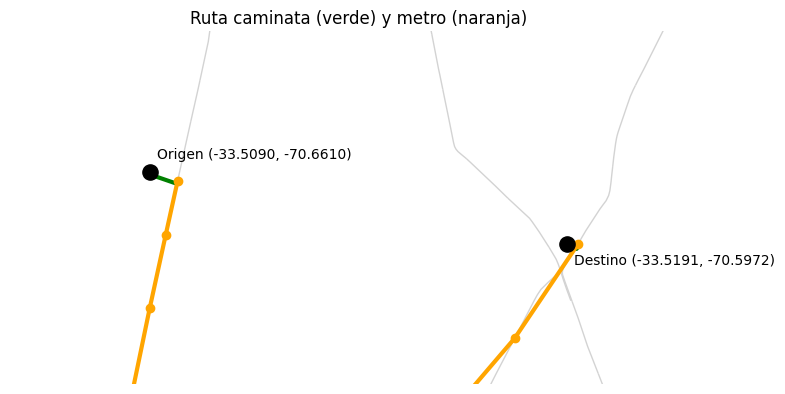

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
lineas_metro.plot(ax=ax, color="lightgray", linewidth=1)          # fondo: todas las líneas

# tramos a pie (verde)
for camino in [camino_hasta_metro, camino_desde_metro]:
    xs = [red_caminata_m1.nodes[nodo]["x"] for nodo in camino]
    ys = [red_caminata_m1.nodes[nodo]["y"] for nodo in camino]
    ax.plot(xs, ys, color="green", linewidth=3)

# tramo en metro (naranja)
puntos_recorrido = estaciones.geometry[estaciones_recorrido]
ax.plot(puntos_recorrido.x, puntos_recorrido.y, color="orange", linewidth=3, marker="o")

# origen y destino
ax.scatter([origen.x, destino.x], [origen.y, destino.y], color="black", s=120, zorder=5)
ax.annotate("Origen (-33.5090, -70.6610)", (origen.x, origen.y), xytext=(5, 10), textcoords="offset points")
ax.annotate("Destino (-33.5191, -70.5972)", (destino.x, destino.y), xytext=(5, -15), textcoords="offset points")

# zoom: 2 km alrededor del viaje
ax.set_xlim(min(origen.x, destino.x) - 2000, max(origen.x, destino.x) + 2000)
ax.set_ylim(min(origen.y, destino.y) - 2000, max(origen.y, destino.y) + 2000)
ax.set_title("Ruta caminata (verde) y metro (naranja)")
ax.set_axis_off()
plt.show()

**Conclusión.** El tiempo total depende de los supuestos de velocidad y espera. Si la ruta con metro es mucho más rápida que caminar todo el trayecto, conviene usar el metro.

**Patrones que usamos:** "el más cercano" (`distance` + `idxmin`), armar un grafo con `add_edge`, `nearest_nodes` para pasar de un punto a un nodo, `shortest_path`.

# Misión 2: centralidad en Providencia y percepción de seguridad

**Qué nos piden:** encontrar las intersecciones más importantes de Providencia y ver si coinciden con zonas de baja percepción de seguridad. Después repetir con la red ampliada 1,5 km.

**PASO A PASO**

1. Sacar el polígono de Providencia y bajar su red de calles para autos.
2. Calcular, para cada nodo, la intermediación y la cercanía.
3. Poner todo en una tabla con un nodo por fila.
4. Marcar como críticos los nodos que están en el 10 % más alto de las dos medidas.
5. Promediar la seguridad a menos de 100 m de cada nodo y comparar críticos contra el resto.
6. Repetir con la red ampliada y ver cuántos nodos importantes se mantienen.

### Paso 1: red vial de Providencia

Primero filtramos la fila de Providencia y después sacamos su polígono.

> **`tabla.loc[condición, "columna"]`** filtra filas y elige una columna al mismo tiempo. Lo usamos mucho:
> `comunas.loc[comunas["Comuna"] == "Providencia", "geometry"]` = "de las filas donde la comuna es Providencia, dame la columna geometry".

In [ ]:
comunas.loc[comunas["Comuna"] == "Providencia", ["Comuna", "geometry"]]

,Comuna,geometry
6,Providencia,"POLYGON ((352667.982 6299779.22, 352705.413 62..."


In [ ]:
poligono_prov = comunas.loc[comunas["Comuna"] == "Providencia", "geometry"].iloc[0]   # el polígono, sin la tabla
print("área de Providencia:", round(poligono_prov.area / 1e6, 1), "km²")              # .area está en m²

red_prov_descargada = obtener_red(poligono_prov, "drive", "red_providencia.graphml")
red_prov = red_simple(red_prov_descargada)

print("nodos:", red_prov.number_of_nodes())
print("aristas:", red_prov.number_of_edges())

área de Providencia: 14.4 km²
nodos: 1617
aristas: 2448


### Paso 2: intermediación y cercanía

- **Intermediación** (betweenness): por cuántos caminos mínimos pasa cada nodo. Alta = mucho tránsito pasaría por ahí.
- **Cercanía** (closeness): qué tan cerca está cada nodo de todos los demás. Alta = desde ahí llego rápido a todas partes.

> **Comando nuevo: `nx.betweenness_centrality(red, k=500, weight="length", seed=1)`**
> - `k=500`: en vez de usar todos los nodos (lento), estima con una muestra de 500.
> - `weight="length"`: los caminos se miden en metros.
> - `seed=1`: la muestra es siempre la misma, así el resultado no cambia cada vez.
> - **Devuelve:** un **diccionario** `{nodo: valor}`.

> **Comando nuevo: `nx.closeness_centrality(red, distance="length")`**
> - Ojo: aquí el argumento se llama `distance`, no `weight`. Hace lo mismo: medir en metros.
> - **Devuelve:** un diccionario `{nodo: valor}`.

In [ ]:
intermediacion = nx.betweenness_centrality(red_prov, k=500, weight="length", seed=1)
cercania = nx.closeness_centrality(red_prov, distance="length")

print(type(intermediacion), "con", len(intermediacion), "nodos")
print("primeros 3:", list(intermediacion.items())[:3])

<class 'dict'> con 1617 nodos
primeros 3: [(388703, 0.010313312693498451), (133663431, 0.010035913312693498), (5905730961, 0.0006191950464396285)]


### Paso 3: una tabla con un nodo por fila

> **Comando nuevo: `ox.graph_to_gdfs(red, edges=False)`**
> - **Recibe:** una red de OSMnx.
> - **Devuelve:** una GeoDataFrame con **un nodo por fila**. El índice (la "fila") es el identificador del nodo.
> - Sin `edges=False` devuelve **dos** tablas: nodos y aristas (calles). Lo usamos así en la Misión 3 para dibujar.

> **`pd.Series(diccionario)`** convierte `{nodo: valor}` en una columna cuyo índice son los nodos. Al asignarla a la tabla, pandas pega cada valor **en la fila del mismo nodo**.

> **`.rename_axis(None)`** solo le borra el nombre al índice (OSMnx lo llama `osmid`). Lo hacemos para que más adelante `sjoin` nombre la columna `index_right`.

In [ ]:
nodos_prov = ox.graph_to_gdfs(red_prov, edges=False)
nodos_prov = nodos_prov[["geometry"]].rename_axis(None)    # nos quedamos solo con la geometría

nodos_prov["intermediacion"] = pd.Series(intermediacion)
nodos_prov["cercania"] = pd.Series(cercania)
nodos_prov.head()

,geometry,intermediacion,cercania
388703,POINT (348734.559 6298004.68),0.010313,0.000343
133663431,POINT (348799.858 6298021.962),0.010036,0.000349
5905730961,POINT (348761.371 6297887.92),0.000619,0.000329
388705,POINT (348296.803 6297920.375),0.000771,0.000306
321324963,POINT (348392.488 6297939.391),0.003791,0.000315


### Paso 4: nodos en el percentil 90

> **Comando nuevo: `columna.quantile(0.9)`** devuelve el valor bajo el cual queda el 90 % de los datos. "Estar en el 10 % más alto" = ser mayor o igual a ese valor.



In [ ]:
umbral_inter = nodos_prov["intermediacion"].quantile(0.9)
umbral_cerc = nodos_prov["cercania"].quantile(0.9)
print("umbral intermediación:", umbral_inter)
print("umbral cercanía:", umbral_cerc)

nodos_prov["top_inter"] = nodos_prov["intermediacion"] >= umbral_inter
nodos_prov["top_cerc"] = nodos_prov["cercania"] >= umbral_cerc
nodos_prov["critico"] = nodos_prov["top_inter"] & nodos_prov["top_cerc"]

nodos_prov.head()

umbral intermediación: 0.04091030357929484
umbral cercanía: 0.0005024903604384798


,geometry,intermediacion,cercania,top_inter,top_cerc,critico
388703,POINT (348734.559 6298004.68),0.010313,0.000343,False,False,False
133663431,POINT (348799.858 6298021.962),0.010036,0.000349,False,False,False
5905730961,POINT (348761.371 6297887.92),0.000619,0.000329,False,False,False
388705,POINT (348296.803 6297920.375),0.000771,0.000306,False,False,False
321324963,POINT (348392.488 6297939.391),0.003791,0.000315,False,False,False


In [ ]:
# sumar una columna de True/False cuenta cuántos True hay
print("en el top de intermediación:", nodos_prov["top_inter"].sum())
print("en el top de cercanía:", nodos_prov["top_cerc"].sum())
print("críticos (las dos):", nodos_prov["critico"].sum())

en el top de intermediación: 162
en el top de cercanía: 162
críticos (las dos): 69


### Paso 5: comparación con la percepción de seguridad

Primero lo **miramos** en un mapa: puntos de seguridad (rojo es peor) y encima los nodos críticos.

> **`tabla.plot(column="col", cmap="RdYlGn", legend=True)`** pinta cada fila según el valor de `col`. `cmap` es la escala de colores (`RdYlGn` = rojo, amarillo, verde).

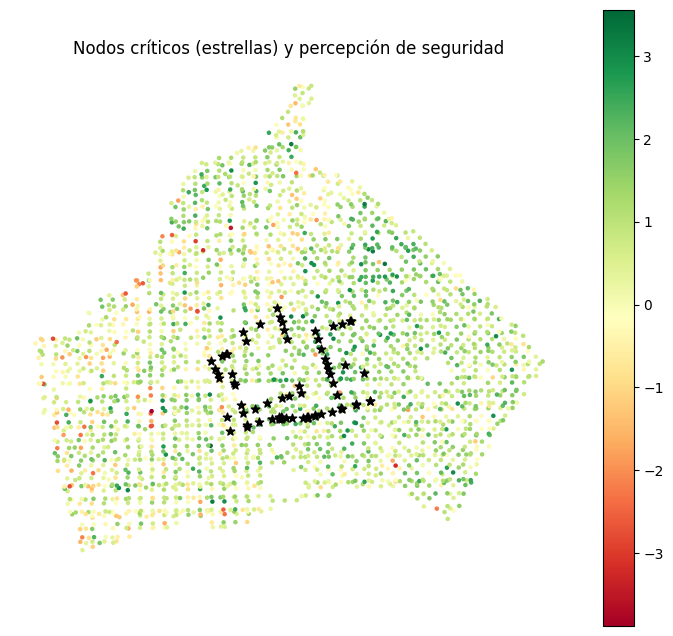

In [ ]:
seguridad_prov = gpd.clip(seguridad, poligono_prov)    # solo los puntos dentro de Providencia

fig, ax = plt.subplots(figsize=(9, 8))
seguridad_prov.plot(ax=ax, column="seguridad", cmap="RdYlGn", markersize=5, legend=True)
nodos_prov[nodos_prov["critico"]].plot(ax=ax, color="black", markersize=40, marker="*")
ax.set_title("Nodos críticos (estrellas) y percepción de seguridad")
ax.set_axis_off()
plt.show()

> **Comando nuevo: `gpd.sjoin(izquierda, derecha, predicate="within")`** (*spatial join*, unión espacial)
> - **Recibe:** dos tablas con geometría. `predicate="within"` = "la geometría de la izquierda está **dentro** de la de la derecha".
> - **Devuelve:** la tabla de la izquierda, **solo con las filas que cayeron dentro de algo**, y una columna nueva **`index_right`** que dice **en qué fila de la derecha** cayó cada una.
> - Si un punto cae en dos círculos, aparece dos veces (una por círculo).

> **Comando nuevo: `tabla.groupby("col")["otra"].mean()`**
> - Junta las filas que tienen el mismo valor en `col` y promedia `otra` dentro de cada grupo (`.sum()` suma, `.mean()` promedia).
> - **Devuelve:** una serie con un valor por grupo.

In [ ]:
# 1) un círculo de 100 m por nodo (conserva el índice = identificador del nodo)
circulos_100m = gpd.GeoDataFrame(geometry=nodos_prov.buffer(100), crs=CRS_METROS)

# 2) qué punto de seguridad cae en qué círculo
seguridad_en_circulos = gpd.sjoin(seguridad_prov, circulos_100m, predicate="within")
seguridad_en_circulos[["seguridad", "index_right"]].head()    # index_right = nodo al que pertenece el punto

,seguridad,index_right
45145,0.001873,388703
45145,0.001873,130018883
45145,0.001873,5609859124
45145,0.001873,131433119
45145,0.001873,131433132


In [ ]:
# 3) promedio de seguridad por nodo
seguridad_por_nodo = seguridad_en_circulos.groupby("index_right")["seguridad"].mean()
print(seguridad_por_nodo.head())

nodos_prov["seg_100m"] = seguridad_por_nodo     # se pega en la fila de cada nodo

index_right
388703     -0.116698
388705      0.132815
13876993    0.649584
13876995    1.247461
13876998    0.968929
Name: seguridad, dtype: float64


In [ ]:
seg_criticos = nodos_prov.loc[nodos_prov["critico"], "seg_100m"].mean()
seg_resto = nodos_prov.loc[~nodos_prov["critico"], "seg_100m"].mean()

print("seguridad promedio cerca de nodos críticos:", round(seg_criticos, 3))
print("seguridad promedio cerca del resto:", round(seg_resto, 3))

seguridad promedio cerca de nodos críticos: 1.039
seguridad promedio cerca del resto: 0.699


### Paso 6: red con buffer de 1,5 km

Repetimos la intermediación con la red **ampliada 1,5 km**. Los nodos de OpenStreetMap tienen el mismo identificador en ambas redes, así que el resultado se pega directo en `nodos_prov` (solo en los nodos de Providencia).

> **Comando nuevo: `columna.nlargest(n)`** devuelve los `n` valores más grandes (con su índice).

> **Conjuntos (`set`)**: `set(lista)` quita repetidos y permite `a & b` = los que están en ambos.

In [ ]:
red_ampliada_descargada = obtener_red(poligono_prov.buffer(1500), "drive", "red_providencia_1500.graphml")
red_ampliada = red_simple(red_ampliada_descargada)
print("nodos red ampliada:", red_ampliada.number_of_nodes())

intermediacion_ampliada = nx.betweenness_centrality(red_ampliada, k=500, weight="length", seed=1)
nodos_prov["inter_ampliada"] = pd.Series(intermediacion_ampliada)

nodos red ampliada: 5060


In [ ]:
top_antes = set(nodos_prov.index[nodos_prov["top_inter"]])                        # identificadores de los top antes
cuantos = len(top_antes)
top_despues = set(nodos_prov["inter_ampliada"].nlargest(cuantos).index)          # la misma cantidad, con la red nueva

se_mantienen = top_antes & top_despues
print("top antes:", cuantos, "| se mantienen:", len(se_mantienen))
print(f"nodos del percentil 90 que se mantienen: {100 * len(se_mantienen) / cuantos:.0f} %")

top antes: 162 | se mantienen: 71
nodos del percentil 90 que se mantienen: 44 %


**Conclusión.** Si la seguridad cerca de los nodos críticos es menor que en el resto, las zonas importantes de la red coinciden con baja percepción. Si es igual o mayor, no coinciden.

Al ampliar la red cambian los nodos importantes cerca del borde, porque aparecen caminos que salen de la comuna. Mientras menos nodos se mantengan, más depende el análisis de dónde cortamos la red.

# Misión 3: cuatro estaciones y la ruta que las conecta

**Qué nos piden:** elegir una estación por cada uno de cuatro criterios, calcular la distancia caminando entre ellas y encontrar la forma más corta de conectarlas.

**Plan en castellano**

1. Criterio i: la estación con más atropellos a 500 m.
2. Criterio ii: la estación con peor seguridad promedio a 500 m.
3. Criterio iii: la estación más cercana al distrito urbano con mayor proporción de grupo E.
4. Criterio iv: la estación más aislada (la que tiene su vecina más lejos).
5. Calcular la distancia caminando entre cada par de estaciones elegidas.
6. Buscar la conexión de menor costo.
7. Dibujarlo.

Los criterios i y ii son **el mismo patrón** de la Misión 2: buffer + sjoin + groupby.

### Paso 1: criterio i, más atropellos a 500 m

1. Dibujo un círculo de 500 m alrededor de cada estación.
2. Veo en qué círculo cae cada atropello.
3. Sumo los atropellos de cada círculo.
4. Me quedo con el círculo que suma más.

La columna `Atropellos` dice **cuántos** atropellos hubo en ese punto (puede ser más de uno), por eso sumamos esa columna en vez de contar filas.

In [ ]:
# 1) un círculo de 500 m por estación; su índice es el número de fila de la estación
circulos_500m = gpd.GeoDataFrame(geometry=estaciones.buffer(500), crs=CRS_METROS)

# 2) en qué círculo cae cada atropello
atropellos_en_circulos = gpd.sjoin(accidentes["atropellos"], circulos_500m, predicate="within")
atropellos_en_circulos[["Atropellos", "index_right"]].head()      # index_right = fila de la estación

,Atropellos,index_right
220,1,12
134,1,10
113,1,10
132,5,10
130,2,10


In [ ]:
# 3) sumamos por estación
atropellos_por_estacion = atropellos_en_circulos.groupby("index_right")["Atropellos"].sum()
print(atropellos_por_estacion.sort_values(ascending=False).head())   # las 5 con más

# 4) la estación con más
fila_mas_atropellos = atropellos_por_estacion.idxmax()
print(estaciones["NOMBRE"][fila_mas_atropellos], "con", atropellos_por_estacion.max(), "atropellos")

index_right
108    17
97     16
91     13
109    12
3      12
Name: Atropellos, dtype: int32
Cal y Canto con 17 atropellos


### Paso 2: criterio ii, peor seguridad a 500 m

Lo mismo, cambiando tres cosas: los puntos (`seguridad`), la operación (`mean` en vez de `sum`) y el mínimo (`idxmin`).

In [ ]:
seguridad_en_circulos = gpd.sjoin(seguridad, circulos_500m, predicate="within")
seguridad_por_estacion = seguridad_en_circulos.groupby("index_right")["seguridad"].mean()

fila_mas_insegura = seguridad_por_estacion.idxmin()
print(estaciones["NOMBRE"][fila_mas_insegura], "con seguridad promedio", round(seguridad_por_estacion.min(), 3))

Santa Rosa con seguridad promedio -0.636


### Paso 3: criterio iii, cerca del distrito con más grupo E

1. Quedarnos con los distritos urbanos: al menos la mitad de su área dentro del área urbana.
2. Calcular la proporción de grupo E: `E / ADIMARK_T` (personas del grupo E / total de personas).
3. Elegir el distrito con mayor proporción.
4. Buscar la estación más cercana a ese distrito.


In [ ]:
poligono_urbano = area_urbana.union_all()

# 1) fracción del área de cada distrito que cae dentro del área urbana
area_dentro = distritos.intersection(poligono_urbano).area
fraccion_urbana = area_dentro / distritos.area
distritos_urbanos = distritos[fraccion_urbana >= 0.5].copy()
print("distritos totales:", len(distritos), "| urbanos:", len(distritos_urbanos))

# 2) proporción de grupo E
distritos_urbanos["prop_E"] = distritos_urbanos["E"] / distritos_urbanos["ADIMARK_T"]
distritos_urbanos[["NOM_COM", "NOM_DIS", "E", "ADIMARK_T", "prop_E"]].sort_values("prop_E", ascending=False).head()

distritos totales: 449 | urbanos: 298


,NOM_COM,NOM_DIS,E,ADIMARK_T,prop_E
129,La Pintana,Rey Don Felipe,711.0,3597.0,0.197665
126,La Pintana,Pablo de Rokha,1122.0,6901.0,0.162585
128,La Pintana,La Platina,1439.0,8961.0,0.160585
357,San Bernardo,Santa Marta,674.0,4555.0,0.147969
37,Cerro Navia,Dalmacia,454.0,3070.0,0.147883


In [ ]:
# 3) la fila completa del distrito con mayor proporción
distrito_mas_E = distritos_urbanos.loc[distritos_urbanos["prop_E"].idxmax()]

# 4) la estación más cercana a ese polígono
fila_cerca_grupo_E = estaciones.distance(distrito_mas_E["geometry"]).idxmin()

print("distrito:", distrito_mas_E["NOM_DIS"], "en", distrito_mas_E["NOM_COM"])
print("estación más cercana:", estaciones["NOMBRE"][fila_cerca_grupo_E])

distrito: Rey Don Felipe en La Pintana
estación más cercana: Lo Martínez


### Paso 4: criterio iv, la estación más aislada

Para cada estación buscamos la distancia a su vecina más cercana. Truco: la distancia más chica de una estación a todas es **ella misma** (0 m), así que la vecina es la **segunda** más chica.

Probamos primero con una estación:

In [ ]:
punto = estaciones.geometry[0]
print(estaciones.distance(punto).nsmallest(2))   # la primera es ella misma, con 0 m

0      0.000000
1    922.799527
dtype: float64


In [ ]:
dist_a_vecina = []
for punto in estaciones.geometry:
    dos_menores = estaciones.distance(punto).nsmallest(2)
    dist_a_vecina.append(dos_menores.iloc[1])               # la segunda = la vecina

dist_a_vecina = pd.Series(dist_a_vecina, index=estaciones.index)   # lista -> serie con el mismo índice

fila_mas_aislada = dist_a_vecina.idxmax()
print(estaciones["NOMBRE"][fila_mas_aislada], "a", round(dist_a_vecina.max()), "m de su vecina")

Lo Errázuriz a 1654 m de su vecina


In [ ]:
filas_elegidas = [fila_mas_atropellos, fila_mas_insegura, fila_cerca_grupo_E, fila_mas_aislada]
print("filas elegidas:", filas_elegidas)
print("estaciones elegidas:", list(estaciones["NOMBRE"][filas_elegidas]))

filas elegidas: [np.int64(108), np.int64(10), 64, 68]
estaciones elegidas: ['Cal y Canto', 'Santa Rosa', 'Lo Martínez', 'Lo Errázuriz']


### Paso 5: distancias caminando entre las cuatro

> **Comando nuevo: `combinations(lista, 2)`** (de `itertools`) genera todos los **pares** posibles sin repetir y sin importar el orden. Con 4 estaciones hay 6 pares.

> **`for a, b in pares:`** cada par es una tupla `(a, b)`; esta forma la "desarma" en dos variables.

In [ ]:
pares = list(combinations(filas_elegidas, 2))
print(len(pares), "pares:", pares)

6 pares: [(np.int64(108), np.int64(10)), (np.int64(108), 64), (np.int64(108), 68), (np.int64(10), 64), (np.int64(10), 68), (64, 68)]


Bajamos las calles alrededor de las 6 rectas entre estaciones.

> **Comando nuevo: `unary_union(lista_de_formas)`** junta varias geometrías en una sola (como `union_all`, pero para una lista).

In [ ]:
puntos_elegidos = estaciones.geometry[filas_elegidas]    # serie con 4 puntos; su índice son las filas

rectas = []
for a, b in pares:
    rectas.append(LineString([puntos_elegidos[a], puntos_elegidos[b]]))
corredor = unary_union(rectas).buffer(1200)

red_m3_descargada = obtener_red(corredor, "walk", "red_walk_M3.graphml")
red_caminata_m3 = red_simple(red_m3_descargada)
print("nodos:", red_caminata_m3.number_of_nodes())

nodos: 31645


In [ ]:
# diccionario: fila de la estación -> nodo de la red más cercano
nodo_de_estacion = {}
for fila in filas_elegidas:
    p = puntos_elegidos[fila]
    nodo_de_estacion[fila] = ox.distance.nearest_nodes(red_caminata_m3, X=p.x, Y=p.y)
nodo_de_estacion

{np.int64(108): 11580920749,
 np.int64(10): 2355913043,
 64: 11350194543,
 68: 605139458}

Armamos un grafo chico, `grafo_estaciones`: 4 nodos (las estaciones) y 6 aristas, cada una con la distancia caminando como peso.

In [ ]:
grafo_estaciones = nx.Graph()
for a, b in pares:
    dist_caminando = nx.shortest_path_length(red_caminata_m3, nodo_de_estacion[a], nodo_de_estacion[b], weight="length")
    grafo_estaciones.add_edge(a, b, weight=dist_caminando)
    print(estaciones["NOMBRE"][a], "-", estaciones["NOMBRE"][b], ":", round(dist_caminando), "m")

Cal y Canto - Santa Rosa : 12720 m
Cal y Canto - Lo Martínez : 16067 m
Cal y Canto - Lo Errázuriz : 9970 m
Santa Rosa - Lo Martínez : 6678 m
Santa Rosa - Lo Errázuriz : 12145 m
Lo Martínez - Lo Errázuriz : 13328 m


### Paso 6: la conexión de menor costo

- **Árbol de expansión mínima:** conectar todas con el menor largo total (puede tener ramas).
- **Mejor recorrido:** una sola ruta que pasa por las cuatro. Probamos todos los órdenes (4! = 24).

> **Comando nuevo: `nx.minimum_spanning_tree(grafo)`**
> - **Recibe:** un grafo con pesos (usa el dato `weight` de las aristas).
> - **Devuelve:** otro grafo, el árbol, con solo las aristas elegidas.

> **`grafo.size(weight="weight")`** suma los pesos de todas las aristas del grafo.

> **`grafo[a][b]["weight"]`** lee el peso de la arista entre `a` y `b`.

In [ ]:
arbol_minimo = nx.minimum_spanning_tree(grafo_estaciones)
print("aristas del árbol:", [(estaciones["NOMBRE"][a], estaciones["NOMBRE"][b]) for a, b in arbol_minimo.edges()])
print(f"árbol mínimo: {arbol_minimo.size(weight='weight') / 1000:.1f} km")

aristas del árbol: [('Cal y Canto', 'Lo Errázuriz'), ('Santa Rosa', 'Lo Martínez'), ('Santa Rosa', 'Lo Errázuriz')]
árbol mínimo: 28.8 km


In [ ]:
def largo_recorrido(orden):
    # suma las distancias entre estaciones consecutivas del orden
    total = 0
    for k in range(len(orden) - 1):
        total += grafo_estaciones[orden[k]][orden[k + 1]]["weight"]
    return total

mejor_orden, largo_mejor = None, float("inf")      # inf = infinito: cualquier largo real es menor
for orden in permutations(filas_elegidas):
    largo = largo_recorrido(orden)
    if largo < largo_mejor:
        mejor_orden, largo_mejor = orden, largo

print("órdenes probados:", len(list(permutations(filas_elegidas))))
print(f"mejor recorrido: {' > '.join(estaciones['NOMBRE'][list(mejor_orden)])} ({largo_mejor / 1000:.1f} km)")

órdenes probados: 24
mejor recorrido: Cal y Canto > Lo Errázuriz > Santa Rosa > Lo Martínez (28.8 km)


### Paso 7: mapa del árbol mínimo

Cada arista del árbol es solo un número, así que para dibujarla volvemos a pedir el camino real por las calles.


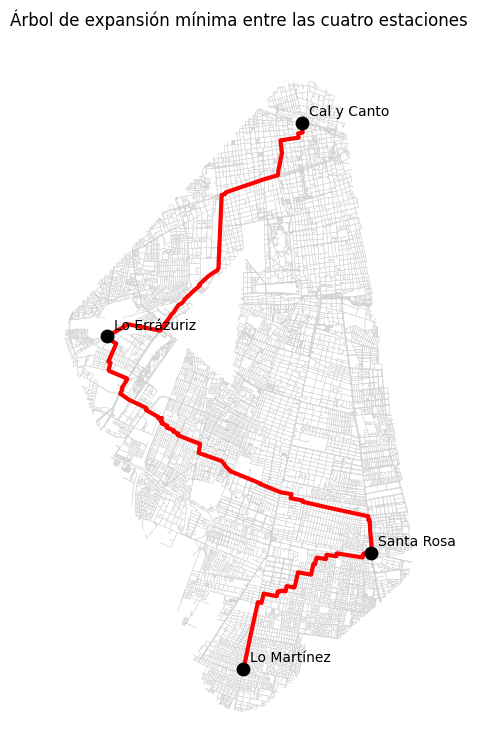

In [ ]:
_, calles_m3 = ox.graph_to_gdfs(red_m3_descargada)

fig, ax = plt.subplots(figsize=(9, 9))
calles_m3.plot(ax=ax, color="lightgray", linewidth=0.3)

for a, b in arbol_minimo.edges():
    camino = nx.shortest_path(red_caminata_m3, nodo_de_estacion[a], nodo_de_estacion[b], weight="length")
    xs = [red_caminata_m3.nodes[nodo]["x"] for nodo in camino]
    ys = [red_caminata_m3.nodes[nodo]["y"] for nodo in camino]
    ax.plot(xs, ys, color="red", linewidth=3)

for fila in filas_elegidas:
    p = puntos_elegidos[fila]
    ax.scatter(p.x, p.y, color="black", s=80, zorder=5)
    ax.annotate(estaciones["NOMBRE"][fila], (p.x, p.y), xytext=(5, 5), textcoords="offset points")

ax.set_title("Árbol de expansión mínima entre las cuatro estaciones")
ax.set_axis_off()
plt.show()

**Conclusión.** El árbol mínimo nunca es más largo que el recorrido único, porque un recorrido es un árbol sin ramas. El árbol sirve para planificar infraestructura y el recorrido sirve para una persona que debe pasar por las cuatro estaciones.

**Patrones que usamos:** buffer + sjoin + groupby (dos veces), "el más cercano", `combinations` para los pares, `permutations` para los órdenes, `minimum_spanning_tree`.

# Misión 4: puntos de control en La Florida

**Qué nos piden:** encontrar las intersecciones críticas de La Florida usando la red y los accidentes, proponer tres puntos de control y comparar qué tan bien cubren la comuna (excentricidad).

**Paso a paso**

1. Bajar la red de La Florida y calcular para cada nodo su grado y su intermediación.
2. Juntar las cuatro bases de accidentes y asignar cada accidente a su nodo más cercano.
3. Ver en qué puesto está La Florida en delitos comparada con las otras comunas.
4. Darle un puntaje a cada nodo (intermediación + accidentes) y elegir los tres mejores que estén separados.
5. Calcular la excentricidad de esos tres.

### Paso 1: red y centralidad

- **Grado:** cuántas calles llegan a la intersección.
- **Intermediación:** cuánto tránsito pasaría por ella (como en la Misión 2).

> **Comando nuevo: `red.degree()`** entrega pares `(nodo, grado)`. Con `dict(...)` lo convertimos en diccionario `{nodo: grado}`, igual que lo que devuelve la centralidad.

In [ ]:
poligono_florida = comunas.loc[comunas["Comuna"] == "La Florida", "geometry"].iloc[0]
red_florida = red_simple(obtener_red(poligono_florida, "drive", "red_laflorida.graphml"))

nodos_florida = ox.graph_to_gdfs(red_florida, edges=False)[["geometry"]].rename_axis(None)

grado = dict(red_florida.degree())
print("ejemplo de grados:", list(grado.items())[:3])

nodos_florida["grado"] = pd.Series(grado)
nodos_florida["intermediacion"] = pd.Series(nx.betweenness_centrality(red_florida, k=300, weight="length", seed=1))
print("nodos:", len(nodos_florida))
nodos_florida.head()

ejemplo de grados: [(16106404, 4), (493702451, 4), (1262306828, 3)]
nodos: 7819


,geometry,grado,intermediacion
16106404,POINT (351859.745 6288778.715),4,0.066244
493702451,POINT (351880.141 6288780.714),4,0.053938
1262306828,POINT (351889.309 6288699.146),3,0.031449
16106412,POINT (351891.605 6288781.778),4,0.089374
9393255399,POINT (351983.114 6288786.99),3,0.049400


### Paso 2: accidentes por nodo

Las cuatro bases guardan la cantidad de accidentes en columnas con **nombres distintos** (`Atropellos` en una, `Accidentes` en las otras). Para juntarlas, de cada una tomamos la geometría y esa columna, y la renombramos a `cantidad`.

> **Comando nuevo: `tabla.rename(columns={"viejo": "nuevo"})`** cambia el nombre de columnas.

> **Comando nuevo: `pd.concat([tabla1, tabla2, ...])`** pone las tablas **una debajo de la otra**. Tienen que tener las mismas columnas.

> **`.items()`** de un diccionario entrega pares `(llave, valor)`.

In [ ]:
columna_cantidad = {"atropellos": "Atropellos", "bicicletas": "Accidentes", "motos": "Accidentes", "criticos": "Accidentes"}

partes = []
for nombre, columna in columna_cantidad.items():
    parte = accidentes[nombre][["geometry", columna]].rename(columns={columna: "cantidad"})
    print(nombre, ":", len(parte), "filas")
    partes.append(parte)

accidentes_florida = pd.concat(partes)
accidentes_florida = gpd.GeoDataFrame(accidentes_florida, crs=CRS_METROS)   # concat devuelve tabla normal; la volvemos GeoDataFrame
accidentes_florida = gpd.clip(accidentes_florida, poligono_florida)
print("accidentes en La Florida:", len(accidentes_florida))
accidentes_florida.head()

atropellos : 866 filas
bicicletas : 957 filas
motos : 2095 filas
criticos : 771 filas
accidentes en La Florida: 201


,geometry,cantidad
230,POINT (350461.09 6286125.656),1
717,POINT (350610.199 6286518.168),1
1130,POINT (350663.482 6287926.267),1
231,POINT (350434.066 6290868.1),1
1090,POINT (350255.638 6291051.242),1


Asignamos cada accidente a su esquina más cercana. Ahora le pasamos a `nearest_nodes` **todas** las x e y de una vez, y con `return_dist=True` nos dice además a cuántos metros quedó la esquina. Si está a más de 100 m, no lo contamos.

In [ ]:
nodo_cercano, dist_al_nodo = ox.distance.nearest_nodes(
    red_florida,
    X=accidentes_florida.geometry.x,
    Y=accidentes_florida.geometry.y,
    return_dist=True,
)
accidentes_florida["nodo"] = nodo_cercano
accidentes_florida["dist_al_nodo"] = dist_al_nodo
accidentes_florida.head()

,geometry,cantidad,nodo,dist_al_nodo
230,POINT (350461.09 6286125.656),1,2011264933,1.623470
717,POINT (350610.199 6286518.168),1,4488907264,4.105112
1130,POINT (350663.482 6287926.267),1,425944586,0.990851
231,POINT (350434.066 6290868.1),1,4458277604,41.840018
1090,POINT (350255.638 6291051.242),1,4856230292,102.833638


In [ ]:
accidentes_florida = accidentes_florida[accidentes_florida["dist_al_nodo"] <= 100]   # descartamos los lejanos

accidentes_por_nodo = accidentes_florida.groupby("nodo")["cantidad"].sum()
nodos_florida["accidentes"] = accidentes_por_nodo
nodos_florida["accidentes"] = nodos_florida["accidentes"].fillna(0)    # nodos sin accidentes: NaN -> 0

print("accidentes asignados:", int(nodos_florida["accidentes"].sum()))
nodos_florida.sort_values("accidentes", ascending=False).head()

accidentes asignados: 448


,geometry,grado,intermediacion,accidentes
490521914,POINT (351556.149 6289575.872),4,0.072099,23.0
427977390,POINT (350979.728 6291140.138),3,0.000339,19.0
9579269256,POINT (350162.215 6291152.274),3,0.000127,19.0
583684322,POINT (352585.172 6286919.642),4,0.016440,18.0
3896786218,POINT (351917.113 6290152.728),4,0.015261,17.0


> **`fillna(0)`**: cuando pegamos `accidentes_por_nodo`, los nodos que no aparecen ahí quedan vacíos (`NaN`). `fillna(0)` los rellena con 0.

### Paso 3: delitos

Los delitos solo vienen por comuna (columna `UnddTrr` = unidad territorial), así que solo podemos ver **en qué puesto** está La Florida.

> **Comando nuevo: `columna.apply(funcion)`** aplica una función a cada valor de la columna. Aquí aplicamos `norm` para que los nombres sean comparables sin importar tildes o mayúsculas.

> **Comando nuevo: `columna.rank(ascending=False)`** le da a cada fila su puesto: 1 = el valor más alto.

In [ ]:
archivos_delitos = {
    "robos con violencia": "imfd-delitos-24-robbery-with-violence-or-intimidation/IMFD-Delitos-24-robbery with violence or intimidation.shp",
    "hurtos": "imfd-delitos-13-thefts/IMFD-Delitos-13-Thefts.shp",
}

delitos = gpd.read_file(ruta + "Delitos/" + archivos_delitos["robos con violencia"])
delitos[["UnddTrr", "Total"]].head()

,UnddTrr,Total
0,SANTIAGO,3254.264992
1,CERRILLOS,2873.248051
2,CERRO NAVIA,1882.717475
3,CONCHALI,2809.041924
4,EL BOSQUE,2287.972102


In [ ]:
for tipo, archivo in archivos_delitos.items():
    delitos = gpd.read_file(ruta + "Delitos/" + archivo)
    delitos["clave"] = delitos["UnddTrr"].apply(norm)            # "La Florida" -> "LA FLORIDA"
    delitos["puesto"] = delitos["Total"].rank(ascending=False)
    puesto_florida = delitos.loc[delitos["clave"] == "LA FLORIDA", "puesto"].iloc[0]
    print(f"{tipo}: La Florida está en el puesto {puesto_florida:.0f} de {len(delitos)}")

robos con violencia: La Florida está en el puesto 25 de 52
hurtos: La Florida está en el puesto 6 de 52


### Paso 4: tres puntos de control

**El puntaje.** Intermediación y accidentes están en escalas muy distintas (0,001 contra 5), así que no se pueden sumar directo.

> **Comando nuevo: `columna.rank(pct=True)`** convierte cada valor en su **percentil** entre 0 y 1 (1 = el más alto). Así las dos columnas quedan en la misma escala y se pueden promediar.

In [ ]:
nodos_florida["pct_inter"] = nodos_florida["intermediacion"].rank(pct=True)
nodos_florida["pct_acc"] = nodos_florida["accidentes"].rank(pct=True)
nodos_florida["puntaje"] = 0.5 * nodos_florida["pct_inter"] + 0.5 * nodos_florida["pct_acc"]

nodos_florida.sort_values("puntaje", ascending=False)[["intermediacion", "accidentes", "pct_inter", "pct_acc", "puntaje"]].head()

,intermediacion,accidentes,pct_inter,pct_acc,puntaje
6061423457,0.095940,2.0,0.994756,0.994948,0.994852
490521914,0.072099,23.0,0.988234,1.000000,0.994117
493880174,0.147679,1.0,1.000000,0.987339,0.993669
794742899,0.127817,1.0,0.999361,0.987339,0.993350
1925768329,0.105479,1.0,0.997570,0.987339,0.992454


**Elegir tres separados.** Los tres primeros probablemente están en la misma esquina. Recorremos del mejor al peor y **aceptamos uno solo si está a 2 km o más de todos los que ya elegimos**. Paramos al tener tres.

In [ ]:
nodos_ordenados = nodos_florida.sort_values("puntaje", ascending=False).index

puntos_control = []
for nodo in nodos_ordenados:
    lejos_de_todos = True
    for elegido in puntos_control:
        if nodos_florida.geometry[nodo].distance(nodos_florida.geometry[elegido]) < 2000:
            lejos_de_todos = False
    if lejos_de_todos:
        puntos_control.append(nodo)
    if len(puntos_control) == 3:
        break

nodos_florida.loc[puntos_control, ["grado", "intermediacion", "accidentes", "puntaje"]]

,grado,intermediacion,accidentes,puntaje
6061423457,3,0.095940,2.0,0.994852
490521914,4,0.072099,23.0,0.994117
493880174,4,0.147679,1.0,0.993669


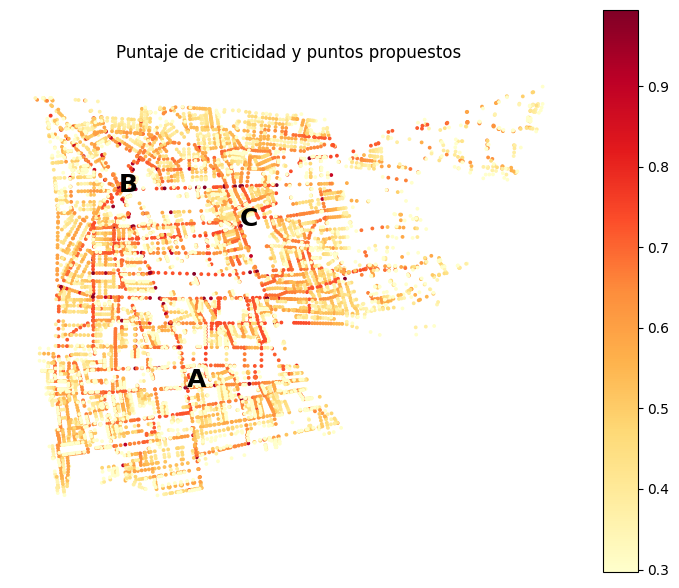

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
nodos_florida.plot(ax=ax, column="puntaje", cmap="YlOrRd", markersize=3, legend=True)
for letra, nodo in zip("ABC", puntos_control):          # zip recorre las dos listas en paralelo: ("A", 1er nodo), ("B", 2do)...
    p = nodos_florida.geometry[nodo]
    ax.annotate(letra, (p.x, p.y), fontsize=18, fontweight="bold")
ax.set_title("Puntaje de criticidad y puntos propuestos")
ax.set_axis_off()
plt.show()

### Paso 5: excentricidad y cobertura

> **Comando nuevo: `nx.eccentricity(red, v=nodo, weight="length")`** devuelve la distancia desde ese nodo hasta el nodo **más lejano** de la red. Mientras más baja, mejor cubre ese punto toda la comuna.

`nx.closeness_centrality(red, u=nodo, ...)` con `u=` calcula la cercanía de **un solo** nodo (sin `u` la calcula para todos).

In [ ]:
for letra, nodo in zip("ABC", puntos_control):
    excentricidad = nx.eccentricity(red_florida, v=nodo, weight="length")
    cercania_nodo = nx.closeness_centrality(red_florida, u=nodo, distance="length")
    print(f"{letra}: excentricidad {excentricidad:.0f} m, cercanía {cercania_nodo:.6f}, accidentes {nodos_florida['accidentes'][nodo]:.0f}")

A: excentricidad 10608 m, cercanía 0.000280, accidentes 2
B: excentricidad 8257 m, cercanía 0.000293, accidentes 23
C: excentricidad 7599 m, cercanía 0.000306, accidentes 1


**Conclusión.** El punto con menor excentricidad es el que mejor cubre la comuna. Si no coincide con el más crítico, hay que elegir: vigilar donde ocurren más accidentes o poder llegar rápido a toda la comuna.

**Patrones que usamos:** `rename` + `concat` para juntar tablas, `nearest_nodes` con distancia, `groupby` por nodo, `rank(pct=True)` para combinar escalas, y **elegir los mejores pero separados**.

# Misión 5: zonas de accidentes de bicicleta y moto

**Qué nos piden:** encontrar cinco zonas con muchos accidentes de bicicleta y moto, conectarlas con un grafo completo y compararlo con su árbol de expansión mínima.

**Paso a paso**

1. Dividir Santiago en cuadrados de 1 km × 1 km y contar los accidentes de bici y moto en cada uno.
2. Elegir los cinco cuadrados con más accidentes, separados al menos 2 km.
3. Conectar cada par de zonas con su distancia en bicicleta (grafo completo).
4. Calcular el árbol mínimo y compararlo.

### Paso 1: grilla de 1 km

> **`tabla.total_bounds`** entrega el rectángulo que encierra todo: `xmin, ymin, xmax, ymax`.

> **Comando nuevo: `np.arange(inicio, fin, paso)`** genera los números desde `inicio` hasta `fin` (sin incluirlo), de `paso` en `paso`.

> **Comando nuevo: `box(xmin, ymin, xmax, ymax)`** crea un rectángulo.

In [ ]:
accidentes_bici_moto = pd.concat([accidentes["bicicletas"], accidentes["motos"]])[["geometry", "Accidentes"]]
print("puntos de accidentes:", len(accidentes_bici_moto))

xmin, ymin, xmax, ymax = area_urbana.total_bounds
xs_esquina = np.arange(xmin, xmax, 1000)    # x de la esquina izquierda de cada cuadrado
ys_esquina = np.arange(ymin, ymax, 1000)    # y de la esquina de abajo
print(len(xs_esquina), "columnas x", len(ys_esquina), "filas")

puntos de accidentes: 3052
31 columnas x 40 filas


In [ ]:
cuadrados = []
for x in xs_esquina:
    for y in ys_esquina:
        cuadrados.append(box(x, y, x + 1000, y + 1000))

grilla = gpd.GeoDataFrame(geometry=cuadrados, crs=CRS_METROS)
print("celdas:", len(grilla))

celdas: 1240


Contar accidentes por celda es otra vez **sjoin + groupby**: `index_right` ahora es la fila de la celda.

In [ ]:
accidentes_en_celdas = gpd.sjoin(accidentes_bici_moto, grilla, predicate="within")
grilla["total"] = accidentes_en_celdas.groupby("index_right")["Accidentes"].sum()
grilla["total"] = grilla["total"].fillna(0)

grilla.sort_values("total", ascending=False).head()

,geometry,total
664,"POLYGON ((349831.771 6299207.014, 349831.771 6...",58.0
705,"POLYGON ((350831.771 6300207.014, 350831.771 6...",49.0
663,"POLYGON ((349831.771 6298207.014, 349831.771 6...",40.0
542,"POLYGON ((346831.771 6297207.014, 346831.771 6...",39.0
622,"POLYGON ((348831.771 6297207.014, 348831.771 6...",39.0


### Paso 2: cinco zonas prioritarias

**La misma elección que en la Misión 4**: de mayor a menor, aceptando una celda solo si está a 2 km o más de las ya elegidas.

In [ ]:
celdas_elegidas = []
for fila in grilla.sort_values("total", ascending=False).index:
    centro = grilla.geometry[fila].centroid
    lejos_de_todas = True
    for elegida in celdas_elegidas:
        if centro.distance(grilla.geometry[elegida].centroid) < 2000:
            lejos_de_todas = False
    if lejos_de_todas:
        celdas_elegidas.append(fila)
    if len(celdas_elegidas) == 5:
        break

# diccionario: nombre de la zona -> punto central
centro_zona = {}
for posicion, fila in enumerate(celdas_elegidas):
    centro_zona[f"Z{posicion + 1}"] = grilla.geometry[fila].centroid

for zona, fila in zip(centro_zona, celdas_elegidas):
    print(zona, ":", int(grilla["total"][fila]), "accidentes")

Z1 : 58 accidentes
Z2 : 39 accidentes
Z3 : 39 accidentes
Z4 : 32 accidentes
Z5 : 31 accidentes


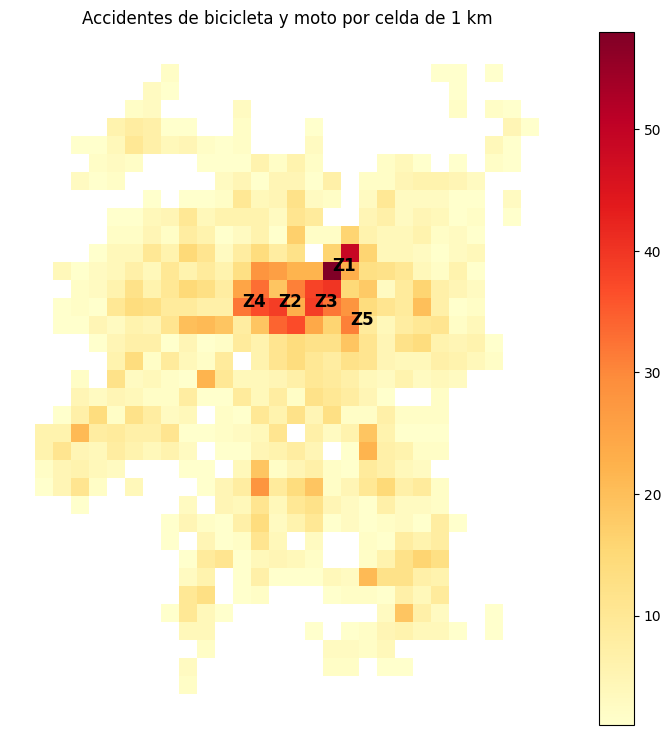

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
grilla[grilla["total"] > 0].plot(ax=ax, column="total", cmap="YlOrRd", legend=True)
for zona, centro in centro_zona.items():
    ax.annotate(zona, (centro.x, centro.y), fontsize=12, fontweight="bold")
ax.set_title("Accidentes de bicicleta y moto por celda de 1 km")
ax.set_axis_off()
plt.show()

### Paso 3: grafo completo entre zonas

Igual que en la Misión 3: corredor alrededor de las rectas, red de calles (ahora `"bike"`), nodo más cercano a cada zona y un grafo chico con la distancia en bicicleta.

In [ ]:
pares_zonas = list(combinations(centro_zona, 2))      # combinations sobre un diccionario usa sus llaves: Z1, Z2...
print(len(pares_zonas), "pares de zonas")

rectas = []
for a, b in pares_zonas:
    rectas.append(LineString([centro_zona[a], centro_zona[b]]))
corredor = unary_union(rectas).buffer(800)

red_bici_descargada = obtener_red(corredor, "bike", "red_bike_M5.graphml")
red_bici = red_simple(red_bici_descargada)

nodo_de_zona = {}
for zona, centro in centro_zona.items():
    nodo_de_zona[zona] = ox.distance.nearest_nodes(red_bici, X=centro.x, Y=centro.y)

10 pares de zonas


In [ ]:
grafo_zonas = nx.Graph()
for a, b in pares_zonas:
    dist_bici = nx.shortest_path_length(red_bici, nodo_de_zona[a], nodo_de_zona[b], weight="length")
    grafo_zonas.add_edge(a, b, weight=dist_bici)
    print(a, "-", b, ":", round(dist_bici), "m")

print(f"grafo completo: {grafo_zonas.number_of_edges()} conexiones, {grafo_zonas.size(weight='weight') / 1000:.1f} km")

Z1 - Z2 : 4100 m
Z1 - Z3 : 2990 m
Z1 - Z4 : 5722 m
Z1 - Z5 : 3471 m
Z2 - Z3 : 2475 m
Z2 - Z4 : 2387 m
Z2 - Z5 : 4784 m
Z3 - Z4 : 4760 m
Z3 - Z5 : 2432 m
Z4 - Z5 : 7069 m
grafo completo: 10 conexiones, 40.2 km


### Paso 4: árbol de expansión mínima

In [ ]:
arbol_zonas = nx.minimum_spanning_tree(grafo_zonas)
print(f"árbol mínimo: {arbol_zonas.number_of_edges()} conexiones, {arbol_zonas.size(weight='weight') / 1000:.1f} km")
print("conexiones:", list(arbol_zonas.edges()))

árbol mínimo: 4 conexiones, 10.3 km
conexiones: [('Z1', 'Z3'), ('Z2', 'Z4'), ('Z2', 'Z3'), ('Z3', 'Z5')]


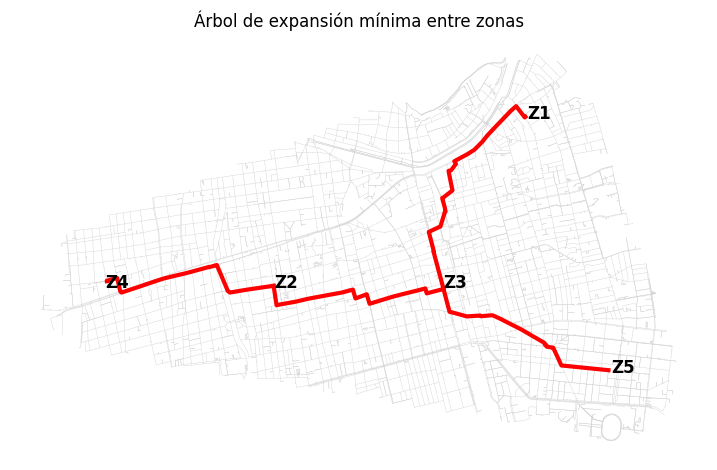

In [ ]:
_, calles_bici = ox.graph_to_gdfs(red_bici_descargada)

fig, ax = plt.subplots(figsize=(9, 9))
calles_bici.plot(ax=ax, color="lightgray", linewidth=0.3)
for a, b in arbol_zonas.edges():
    camino = nx.shortest_path(red_bici, nodo_de_zona[a], nodo_de_zona[b], weight="length")
    xs = [red_bici.nodes[nodo]["x"] for nodo in camino]
    ys = [red_bici.nodes[nodo]["y"] for nodo in camino]
    ax.plot(xs, ys, color="red", linewidth=3)
for zona, centro in centro_zona.items():
    ax.annotate(zona, (centro.x, centro.y), fontsize=12, fontweight="bold")
ax.set_title("Árbol de expansión mínima entre zonas")
ax.set_axis_off()
plt.show()

**Conclusión.** El árbol usa muchos menos kilómetros, así que es más barato. Su riesgo es que no hay caminos alternativos: si se corta un tramo, alguna zona queda aislada. Para un corredor de emergencia conviene el árbol más una o dos conexiones extra que formen un anillo.

**Patrones que usamos:** grilla con dos `for` y `box`, sjoin + groupby por celda, la elección separada de la Misión 4 y el grafo chico + árbol de la Misión 3.

# Misión 6: red intercomunal y flujo máximo

**Qué nos piden:** armar una red donde cada comuna es un nodo, calcular cuántos vehículos por hora pueden ir de una comuna a otra y encontrar los cuellos de botella.

**Paso a paso**

1. Bajar solo las calles grandes (autopistas, troncales y primarias) de las diez comunas.
2. Darle a cada calle una capacidad según su tipo.
3. Decir a qué comuna pertenece cada esquina. Cada calle que cruza de una comuna a otra suma su capacidad a la conexión entre esas comunas.
4. Elegir origen (más robos) y destino (menos robos por habitante).
5. Calcular el flujo máximo.
6. Encontrar el corte mínimo: las conexiones que limitan el flujo.

### Paso 1: red principal de las diez comunas

> **Comando nuevo: `columna.isin(lista)`** da `True` en las filas cuyo valor está en la lista.

> **`custom_filter`** es una opción de OSMnx para bajar solo ciertos tipos de calle. `'["highway"~"motorway|trunk|primary"]'` = "calles cuyo tipo es autopista, troncal o primaria". Llega a OSMnx a través de `**opciones` de `obtener_red`.

In [ ]:
nombres_comunas = ["Santiago", "Independencia", "Recoleta", "Conchalí", "Huechuraba", "Renca",
                   "Quinta Normal", "Estación Central", "Pedro Aguirre Cerda", "San Miguel"]
comunas_m6 = comunas[comunas["Comuna"].isin(nombres_comunas)]
print("comunas encontradas:", len(comunas_m6))

filtro_calles = '["highway"~"motorway|trunk|primary"]'
red_principal = obtener_red(comunas_m6.union_all(), "drive", "red_intercomunal.graphml", custom_filter=filtro_calles)
print("nodos:", red_principal.number_of_nodes(), "aristas:", red_principal.number_of_edges())

comunas encontradas: 10
nodos: 787 aristas: 1059


### Paso 2: capacidad de cada vía

Unos 1.800 vehículos por hora por pista: autopista 3 pistas, troncal 2 y primaria 1 por sentido.

> **`red.edges(data=True)`** recorre las aristas como tríos `(nodo_inicio, nodo_fin, datos)`, donde `datos` es el diccionario de la calle.

In [ ]:
nodo_inicio, nodo_fin, datos_calle = list(red_principal.edges(data=True))[0]   # la primera calle
print(datos_calle["highway"])

primary_link


A veces `highway` es una **lista** (si se unieron dos calles) y a veces termina en `_link` (entradas y salidas). La función maneja los dos casos.

> **`isinstance(x, list)`** pregunta si `x` es una lista. **`diccionario.get(llave, otro)`** devuelve el valor de la llave, o `otro` si no existe.

In [ ]:
CAPACIDAD_POR_TIPO = {"motorway": 5400, "trunk": 3600, "primary": 1800}

def capacidad(datos_calle):
    tipo = datos_calle["highway"]
    if isinstance(tipo, list):
        tipo = tipo[0]
    tipo = tipo.replace("_link", "")               # "trunk_link" -> "trunk"
    return CAPACIDAD_POR_TIPO.get(tipo, 1800)

print(capacidad({"highway": "motorway"}), capacidad({"highway": ["trunk_link", "primary"]}))

5400 3600


### Paso 3: grafo de comunas

**¿A qué comuna pertenece cada esquina?**

> **Comando nuevo: `gpd.sjoin_nearest(izquierda, derecha)`** es como `sjoin`, pero en vez de "dentro de" le pega a cada fila de la izquierda **la fila más cercana** de la derecha. Las esquinas que están dentro de una comuna tienen distancia 0.

In [ ]:
nodos_principal = ox.graph_to_gdfs(red_principal, edges=False)
nodos_con_comuna = gpd.sjoin_nearest(nodos_principal, comunas_m6[["Comuna", "geometry"]])
nodos_con_comuna[["Comuna"]].head()

,Comuna
osmid,
386145,Santiago
10688081677,Santiago
59817646,Santiago
386184,Recoleta
4986979528,Recoleta


Una esquina justo en el límite puede quedar dos veces. **`index.duplicated()`** marca las filas repetidas y con `~` nos quedamos con la primera.

In [ ]:
comuna_de = nodos_con_comuna["Comuna"]
comuna_de = comuna_de[~comuna_de.index.duplicated()]      # comuna_de[nodo] = nombre de su comuna
print(comuna_de.value_counts())                            # cuántas esquinas por comuna

Comuna
Santiago               182
Estación Central       124
Renca                  109
Independencia           72
Recoleta                68
San Miguel              60
Quinta Normal           50
Conchalí                48
Huechuraba              45
Pedro Aguirre Cerda     29
Name: count, dtype: int64


**Armar el grafo de comunas.** Recorremos todas las calles. Si una va de una esquina en la comuna A a una en la comuna B (A distinta de B), sumamos su capacidad a la arista A → B.

> **Comando nuevo: `nx.DiGraph()`** crea un grafo **dirigido**: A → B no es lo mismo que B → A. Lo necesitamos porque el flujo tiene sentido.

> **`grafo.has_edge(a, b)`** pregunta si ya existe la arista.

In [ ]:
grafo_comunas = nx.DiGraph()
for nodo_inicio, nodo_fin, datos_calle in red_principal.edges(data=True):
    comuna_inicio = comuna_de[nodo_inicio]
    comuna_fin = comuna_de[nodo_fin]
    if comuna_inicio == comuna_fin:
        continue                                           # no cruza de comuna: la saltamos
    if grafo_comunas.has_edge(comuna_inicio, comuna_fin):
        grafo_comunas[comuna_inicio][comuna_fin]["capacity"] += capacidad(datos_calle)
    else:
        grafo_comunas.add_edge(comuna_inicio, comuna_fin, capacity=capacidad(datos_calle))

print("conexiones entre comunas:", grafo_comunas.number_of_edges())
for a, b, datos in list(grafo_comunas.edges(data=True))[:5]:
    print(a, "->", b, ":", datos["capacity"], "veh/h")

conexiones entre comunas: 32
Santiago -> Independencia : 12600 veh/h
Santiago -> Pedro Aguirre Cerda : 10800 veh/h
Santiago -> Estación Central : 12600 veh/h
Santiago -> Recoleta : 7200 veh/h
Santiago -> San Miguel : 5400 veh/h


In [ ]:
# capacidad normalizada entre 0 y 1 (la usamos para el grosor de las flechas del mapa)
cap_maxima = max(datos["capacity"] for _, _, datos in grafo_comunas.edges(data=True))
for a, b, datos in grafo_comunas.edges(data=True):
    datos["normalizada"] = datos["capacity"] / cap_maxima

### Paso 4: origen y destino

- **Origen:** la comuna con más robos con violencia.
- **Destino:** la de menor frecuencia relativa: robos / población. La población es la suma de `ADIMARK_T` de los distritos de cada comuna.

Juntamos tres fuentes que escriben los nombres distinto, así que en todas creamos una columna `clave` con `norm`.

> **Comando nuevo: `tabla1.merge(tabla2, on="clave")`** une dos tablas **por una columna en común**, como BUSCARV en Excel.

> **Comando nuevo: `columna.map(serie)`** reemplaza cada valor por el que tiene en `serie` (busca por índice).

In [ ]:
robos = gpd.read_file(ruta + "Delitos/" + archivos_delitos["robos con violencia"])
robos["clave"] = robos["UnddTrr"].apply(norm)

poblacion_comuna = distritos.groupby(distritos["NOM_COM"].apply(norm))["ADIMARK_T"].sum()
poblacion_comuna.head()       # índice: nombre normalizado; valor: población

,ADIMARK_T
NOM_COM,
ALHUE,1190.0
BUIN,16417.0
CALERA DE TANGO,4497.0
CERRILLOS,19406.0
CERRO NAVIA,38683.0


In [ ]:
tabla_robos = pd.DataFrame({"comuna": nombres_comunas})
tabla_robos["clave"] = tabla_robos["comuna"].apply(norm)
tabla_robos = tabla_robos.merge(robos[["clave", "Total"]], on="clave")
tabla_robos["poblacion"] = tabla_robos["clave"].map(poblacion_comuna)
tabla_robos["robos_por_hab"] = tabla_robos["Total"] / tabla_robos["poblacion"]
tabla_robos

,comuna,clave,Total,poblacion,robos_por_hab
0,Santiago,SANTIAGO,3254.264992,71402.0,0.045577
1,Independencia,INDEPENDENCIA,2209.254788,19072.0,0.115838
2,Recoleta,RECOLETA,3762.743681,39084.0,0.096273
3,Conchalí,CONCHALI,2809.041924,35371.0,0.079417
4,Huechuraba,HUECHURABA,1914.228771,18328.0,0.104443
5,Renca,RENCA,2597.613549,34480.0,0.075337
6,Quinta Normal,QUINTA NORMAL,3596.092910,29176.0,0.123255
7,Estación Central,ESTACION CENTRAL,2896.298336,35379.0,0.081865
8,Pedro Aguirre Cerda,PEDRO AGUIRRE CERDA,1989.803656,29724.0,0.066943
9,San Miguel,SAN MIGUEL,2940.518662,22427.0,0.131115


In [ ]:
comuna_origen = tabla_robos.loc[tabla_robos["Total"].idxmax(), "comuna"]
comuna_destino = tabla_robos.loc[tabla_robos["robos_por_hab"].idxmin(), "comuna"]
print("origen:", comuna_origen)
print("destino:", comuna_destino)

origen: Recoleta
destino: Santiago


### Paso 5: flujo máximo

> **Comando nuevo: `nx.maximum_flow_value(grafo, origen, destino)`**
> - Usa el dato **`capacity`** de cada arista (por eso la llamamos así).
> - **Devuelve:** cuántos vehículos por hora pueden ir del origen al destino usando todas las conexiones a la vez sin pasar ninguna capacidad.

In [ ]:
flujo = nx.maximum_flow_value(grafo_comunas, comuna_origen, comuna_destino)
print(f"flujo máximo: {flujo:,.0f} vehículos por hora")
print("¿alcanza para 8.000 vehículos por hora?", flujo >= 8000)

flujo máximo: 18,000 vehículos por hora
¿alcanza para 8.000 vehículos por hora? True


### Paso 6: cuellos de botella

> **Comando nuevo: `nx.minimum_cut(grafo, origen, destino)`**
> - **Devuelve:** dos cosas: el valor del corte (igual al flujo máximo) y una pareja de conjuntos: las comunas del lado del origen y las del lado del destino.
> - Por eso se recibe como `valor, (lado_origen, lado_destino) = ...`.

Las conexiones que **cruzan de un lado al otro** son el cuello de botella.

> **`grafo[comuna]`** entrega los vecinos de esa comuna (a dónde salen flechas).

In [ ]:
valor_corte, (lado_origen, lado_destino) = nx.minimum_cut(grafo_comunas, comuna_origen, comuna_destino)
print("lado origen:", lado_origen)
print("lado destino:", lado_destino)
print("valor del corte:", valor_corte, "(igual al flujo máximo)")

lado origen: {'Recoleta', 'Huechuraba', 'Conchalí'}
lado destino: {'Independencia', 'Quinta Normal', 'Estación Central', 'Santiago', 'Pedro Aguirre Cerda', 'Renca', 'San Miguel'}
valor del corte: 18000 (igual al flujo máximo)


In [ ]:
cuellos_de_botella = []
for comuna in lado_origen:
    for vecina in grafo_comunas[comuna]:
        if vecina in lado_destino:
            cuellos_de_botella.append((comuna, vecina))

print("cuellos de botella:", cuellos_de_botella)

cuellos de botella: [('Recoleta', 'Santiago'), ('Recoleta', 'Independencia'), ('Conchalí', 'Renca'), ('Conchalí', 'Independencia')]


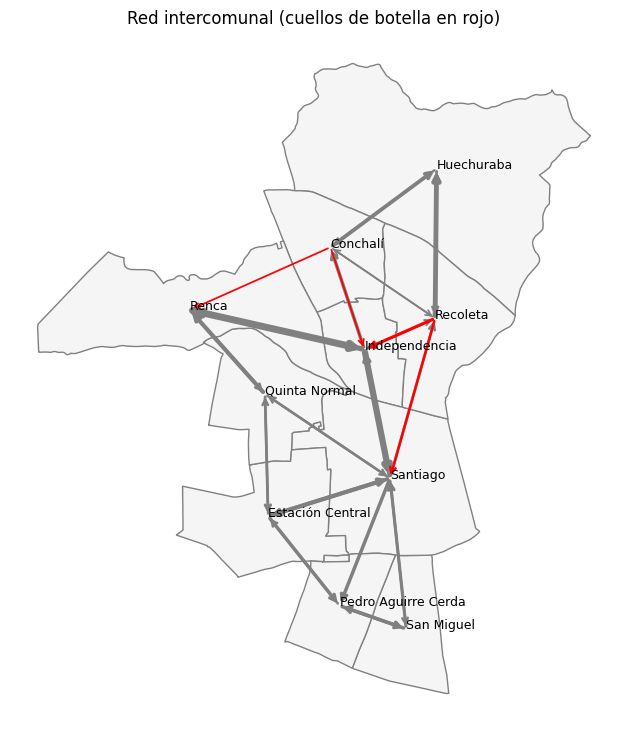

In [ ]:
centro_comuna = comunas_m6.set_index("Comuna").geometry.centroid   # centro_comuna["Renca"] = punto central

fig, ax = plt.subplots(figsize=(9, 9))
comunas_m6.plot(ax=ax, color="whitesmoke", edgecolor="gray")
for a, b, datos in grafo_comunas.edges(data=True):
    color = "red" if (a, b) in cuellos_de_botella else "gray"
    ax.annotate("", xy=(centro_comuna[b].x, centro_comuna[b].y), xytext=(centro_comuna[a].x, centro_comuna[a].y),
                arrowprops=dict(arrowstyle="->", color=color, lw=1 + 4 * datos["normalizada"]))
for nombre in nombres_comunas:
    ax.annotate(nombre, (centro_comuna[nombre].x, centro_comuna[nombre].y), fontsize=9)
ax.set_title("Red intercomunal (cuellos de botella en rojo)")
ax.set_axis_off()
plt.show()

**Conclusión.** Si el flujo máximo supera la demanda, la red alcanza en condiciones normales. Para hacerla más resiliente conviene ampliar las conexiones del corte mínimo o agregar conexiones paralelas, así el flujo no depende de pocas calles.

**Patrones que usamos:** `isin`, recorrer las calles de una red para armar otro grafo, `norm` + `merge` / `map` para juntar tablas por nombre, flujo máximo y corte mínimo.